# ML Evaluation and Interpretability

This notebook compares the framework variants on a common feature set and inspects which aggregate features most influence the scikit-learn baseline.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.ml_model_utils import (
    model_runs_frame,
    reduce_feature_set,
    regression_target,
    run_sklearn_regression_models,
    run_tensorflow_regressor,
    run_torch_regressor,
)
from src.vulkan_math_data import feature_matrix, load_ml_dataset

In [9]:
ml_frame, diagnostics = load_ml_dataset()
X, _ = feature_matrix(ml_frame)
X = reduce_feature_set(X, max_features=12)
y, target_name = regression_target(ml_frame)
display(y.describe())
y = y.fillna(0)
display(y.describe())

sklearn_runs = run_sklearn_regression_models(X, y)
torch_run = run_torch_regressor(X, y, epochs=50)
tensorflow_run = run_tensorflow_regressor(X, y, epochs=50)
all_runs = sklearn_runs + [torch_run, tensorflow_run]
display(model_runs_frame(all_runs))

count    507.000000
mean      71.257396
std       29.773371
min       15.100000
25%       56.200000
50%       66.200000
75%       80.000000
max      183.000000
Name: target__benchmark, dtype: float64

count    547.000000
mean      66.046618
std       34.151084
min        0.000000
25%       48.400000
50%       56.200000
75%       80.000000
max      183.000000
Name: target__benchmark, dtype: float64

,framework,model,mae,r2
0,scikit-learn,ridge,19.743401,0.352409
1,scikit-learn,random_forest,16.979915,0.501744
2,scikit-learn,gradient_boosting,17.252461,0.496862
3,PyTorch,dense_regressor,59.080403,-2.910819
4,TensorFlow,keras_dense_regressor,19.208491,0.405558


In [11]:
ridge_pipeline = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
ridge_pipeline.fit(X, y)
ridge_coefficients = pd.DataFrame(
    {
        "feature": X.columns,
        "coefficient": ridge_pipeline.named_steps["model"].coef_,
    }
).sort_values("coefficient", key=lambda s: s.abs(), ascending=False)
display(ridge_coefficients.head(12))

,feature,coefficient
3,prop__VkPhysicalDeviceVulkan13Properties__maxB...,10.643252
8,prop__VkPhysicalDeviceProperties__limits__spar...,-9.750567
2,prop__VkPhysicalDeviceMaintenance4PropertiesKH...,-8.464095
1,prop__VkPhysicalDeviceVulkan12Properties__maxT...,-8.183494
9,prop__VkPhysicalDeviceDescriptorBufferProperti...,4.607297
11,prop__VkPhysicalDeviceDescriptorBufferProperti...,4.607297
10,prop__VkPhysicalDeviceDescriptorBufferProperti...,4.607297
6,prop__VkPhysicalDeviceTransformFeedbackPropert...,3.780714
0,prop__VkPhysicalDeviceTimelineSemaphorePropert...,3.113501
7,prop__VkPhysicalDeviceExtendedSparseAddressSpa...,1.940765


,feature,importance_mean
3,prop__VkPhysicalDeviceVulkan13Properties__maxB...,0.191047
8,prop__VkPhysicalDeviceProperties__limits__spar...,0.170284
2,prop__VkPhysicalDeviceMaintenance4PropertiesKH...,0.119286
1,prop__VkPhysicalDeviceVulkan12Properties__maxT...,0.112232
9,prop__VkPhysicalDeviceDescriptorBufferProperti...,0.033453
11,prop__VkPhysicalDeviceDescriptorBufferProperti...,0.033453
10,prop__VkPhysicalDeviceDescriptorBufferProperti...,0.033453
6,prop__VkPhysicalDeviceTransformFeedbackPropert...,0.030188
0,prop__VkPhysicalDeviceTimelineSemaphorePropert...,0.017979
7,prop__VkPhysicalDeviceExtendedSparseAddressSpa...,0.005812


/tmp/ipykernel_1395/116815320.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


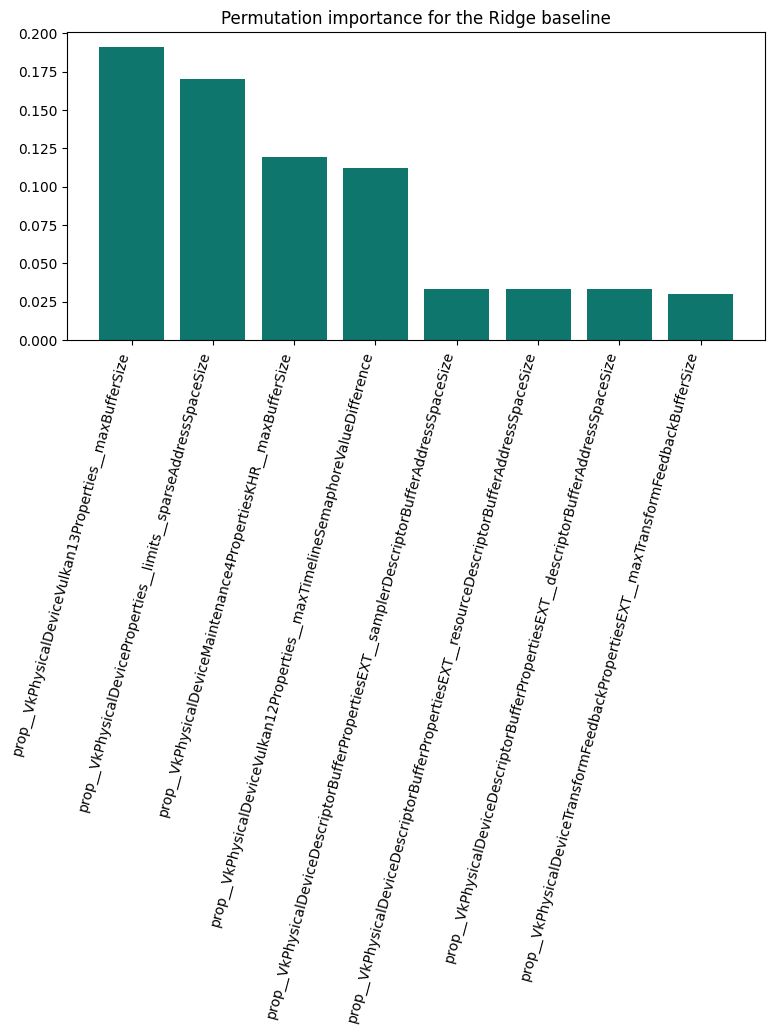

In [12]:
importance = permutation_importance(ridge_pipeline, X, y, n_repeats=5, random_state=7)
importance_frame = pd.DataFrame(
    {
        "feature": X.columns,
        "importance_mean": importance.importances_mean,
    }
).sort_values("importance_mean", ascending=False)
display(importance_frame.head(12))

plt.figure(figsize=(9, 4))
plt.bar(
    importance_frame.head(8)["feature"],
    importance_frame.head(8)["importance_mean"],
    color="#0f766e",
)
plt.xticks(rotation=75, ha="right")
plt.title("Permutation importance for the Ridge baseline")
plt.tight_layout()
plt.show()

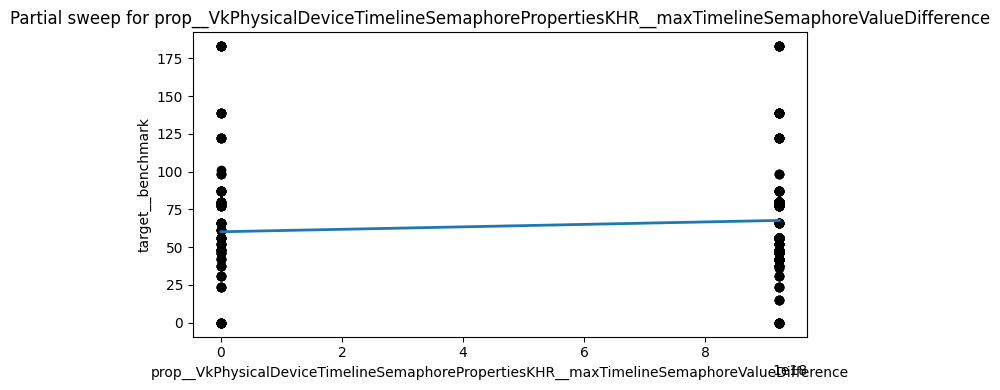

In [13]:
preferred_feature = next(
    (column for column in X.columns if column.startswith("agg__")), X.columns[0]
)
grid = np.linspace(X[preferred_feature].min(), X[preferred_feature].max(), 20)
reference = pd.concat([X.mean().to_frame().T] * len(grid), ignore_index=True)
reference[preferred_feature] = grid
curve = ridge_pipeline.predict(reference)

plt.figure(figsize=(7, 4))
plt.plot(grid, curve, linewidth=2)
plt.scatter(X[preferred_feature], y, color="black")
plt.title(f"Partial sweep for {preferred_feature}")
plt.xlabel(preferred_feature)
plt.ylabel(target_name)
plt.tight_layout()
plt.show()